# 

# Intro à Scikit-Learn – Solution

From:

* [VanderPlas, Jake. 2017. Python Data Science Handbook. O’Reilly Media, Inc.](https://github.com/jakevdp/PythonDataScienceHandbook)
* [Scikit-Learn datasets: The Iris Dataset](https://scikit-learn.org/stable/auto_examples/datasets/plot_iris_dataset.html)

## Classification

### Chargement des données

https://scikit-learn.org/stable/datasets/toy_dataset.html#iris-plants-dataset

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sklearn
from matplotlib.colors import ListedColormap

%config InlineBackend.figure_format="retina"  # For high DPI display

print(sklearn.__version__)  # 1.0.2

1.0.2


In [2]:
from sklearn import datasets

iris = datasets.load_iris()

In [3]:
iris.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [4]:
xs_2d = iris.data[:, :2]
features = iris.feature_names[:2]

if xs_2d.ndim == 1:
    xs_2d = xs_2d[:, np.newaxis]

ys = iris.target

In [5]:
print(features)

['sepal length (cm)', 'sepal width (cm)']


In [6]:
print(xs_2d.shape, ys.shape)

(150, 2) (150,)


Disposition attendue des descripteurs (*features*) et des valeurs cibles (*labels*):

![](img/05.02-samples-features.png)

### Entrainement des modèles

In [7]:
from sklearn.model_selection import train_test_split

xs_train, xs_test, ys_train, ys_test = train_test_split(
    xs_2d, ys, random_state=1
)

In [8]:
# 1. Choix du modèle (classe)
from sklearn.naive_bayes import GaussianNB

# 2. Instantiaiton
model = GaussianNB()

# 3. Apprentissage (fit) du model
model.fit(xs_train, ys_train)

# 4. Prédire sur les données de test
ys_pred = model.predict(xs_test)

### Évaluation

In [9]:
from sklearn.metrics import accuracy_score

score = accuracy_score(ys_test, ys_pred)
print(f"{score :.04f}")

0.8158


### Graphiques

In [10]:
def plot_decision_boundary(xs, model, colors=None, hop=0.01):
    try:
        cmap = ListedColormap(colors.values())
    except AttributeError:
        cmap = None

    # Prepare the data to plot the decision boundary
    # Need to assign a color to each point in the mesh
    # [x1_min, x1_max] x [x2_min, x2_max]

    x_min, x_max = xs[:, 0].min() - 1, xs[:, 0].max() + 1
    y_min, y_max = xs[:, 1].min() - 1, xs[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, hop), np.arange(y_min, y_max, hop)
    )

    zz = model.predict(np.c_[xx.ravel(), yy.ravel()])
    zz = zz.reshape(xx.shape)
    # print(zz.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(
        xx,
        yy,
        zz,
        alpha=0.4,
        cmap=cmap,
        antialiased=True,
    )


def plot_training_points(xs, ys, ft_names=None, target_names=None, colors=None):
    if target_names is None:
        target_names = {}
    if colors is None:
        colors = {}

    for y_val in set(ys):
        plt.scatter(
            xs[ys == y_val, 0],
            xs[ys == y_val, 1],
            color=colors.get(y_val),
            alpha=0.8,
            label=target_names.get(y_val),
            edgecolor="black",
        )
    plt.legend(loc="best", shadow=False, scatterpoints=1)
    plt.title("3-Class classification")
    try:
        plt.xlabel(ft_names[0])
        plt.ylabel(ft_names[1])
    except TypeError:
        pass

In [11]:
HOP = 0.01  # Step size in the mesh

COLORS = {0: "green", 1: "red", 2: "blue"}

target_names = {k: v for k, v in enumerate(iris.target_names)}

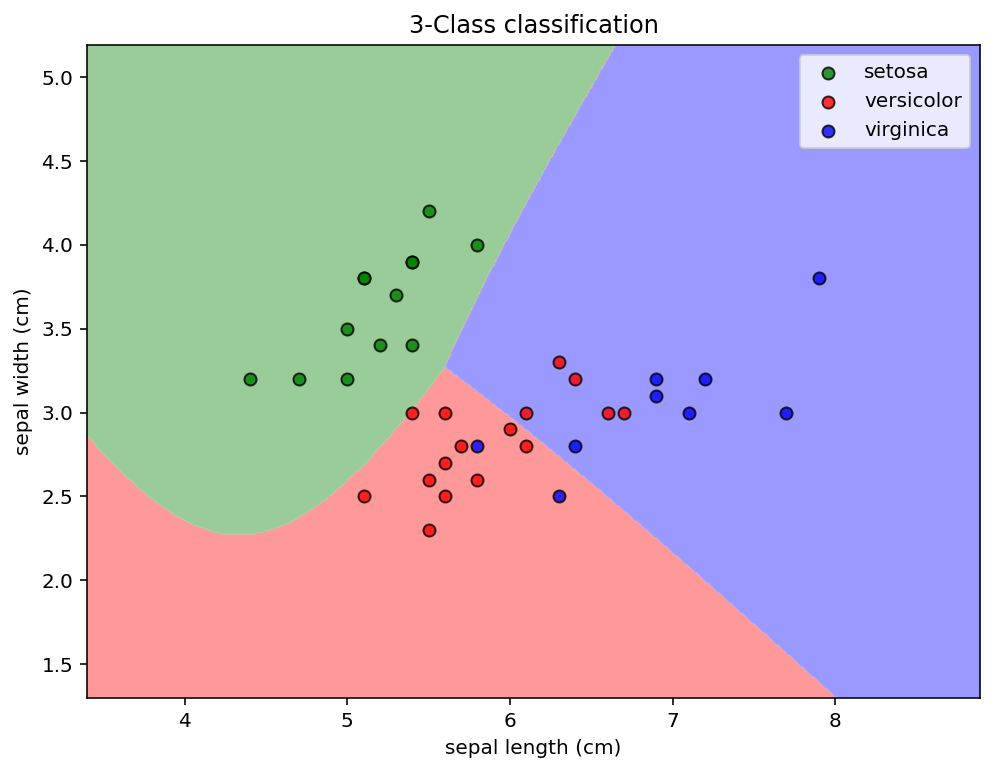

In [12]:
plot_decision_boundary(xs_test, model, COLORS, HOP)
plot_training_points(xs_test, ys_test, features, target_names, COLORS)

## Exercice 1

Chercher dans la [documentation](https://scikit-learn.org/stable/supervised_learning.html) comment appliquer à ce dataset les autres modèles cités au cours :

* Régression logistique (*[Logistic Regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)*)
* Arbre de décision (*[Decision Trees](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html#sklearn.tree.DecisionTreeClassifier)*)
* Forêt d'arbres décisionnels (*[Random Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)*)
* k plus proches voisins (*[k-Nearest Neighbors](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html)*)
* Machine à vecteurs de support (*[Support Vector Machines, SVM](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html#sklearn.svm.SVC)*)

Indiquez les résultats dans un tableau et graphiquement pour chaque système à l'aide des fonctions `plot_...` [ci-dessus](#Graphiques).

Notez les résultats dans un tableau et donnez une courte analyse en comparant les résultats.

<span style="color:red">Implémentez votre solution ci-dessous</span>

In [13]:
# 1. Choix du modèle (classe)
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# 2. Instantiaiton
# model = LogisticRegression(max_iter=100)
# model = DecisionTreeClassifier()
model = RandomForestClassifier(random_state=1)
# model = KNeighborsClassifier(n_neighbors=5)
# model = SVC()

# 3.  Apprentissage (fit) du model
model.fit(xs_train, ys_train)
# 4. predict on new data
ys_pred = model.predict(xs_test)

In [14]:
score = accuracy_score(ys_test, ys_pred)
print(f"{score :.04f}")

0.8158


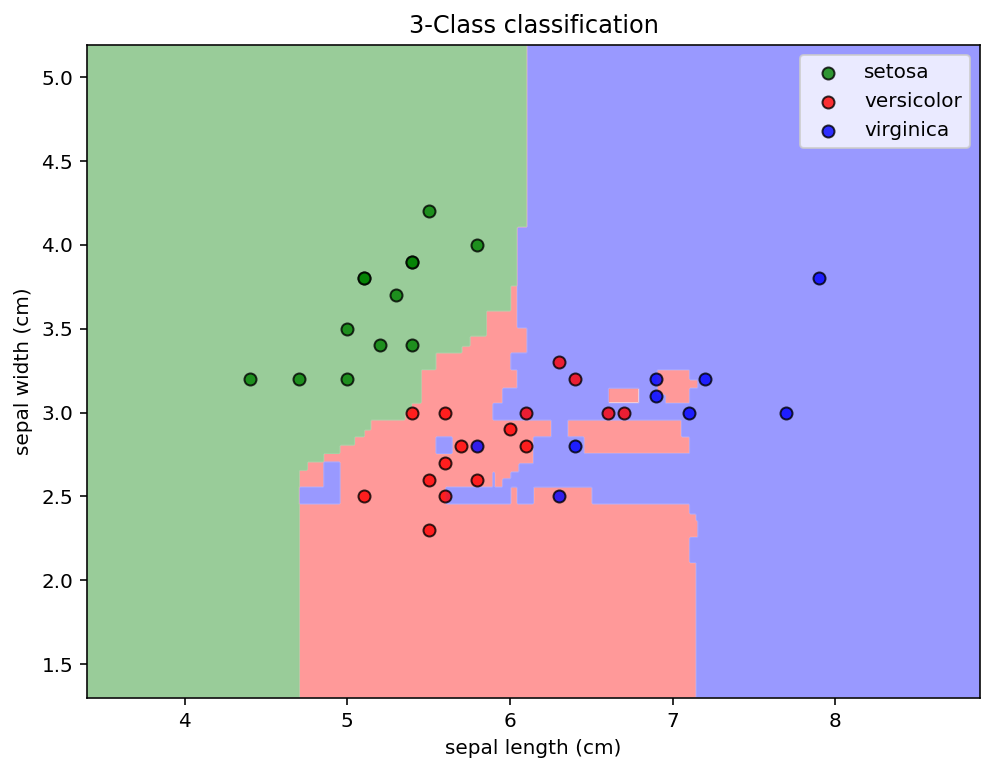

In [15]:
plot_decision_boundary(xs_test, model, COLORS, HOP)
plot_training_points(xs_test, ys_test, features, target_names, COLORS)

| Model                   | Accuracy |
| :--                     | --:      |
| GaussianNB              | 0.8158   |
| LogisticRegression      | 0.7895   |
| DecisionTreeClassifier  | 0.6316   |
| RandomForestClassifier  | 0.8158   |
| KNeighborsRegressor     | 0.7895   |
| SVC                     | 0.8158   |

## Exercice 2

* Appliquez une [Analyse en composantes principales (PCA)](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) aux descripteurs du dataset Iris

* Donnez le pourcentage de variance expliqué par chacune des composantes sélectionnées (`explained_variance_ratio_`), ainsi que leur somme cumulée (`cumsum`)

* Appliquez l'un des classifieurs précédents à la première composante principale, puis aux deux premières composantes principales

* Comparez la qualité des prédictions avec la première et les deux premières composantes principales et les valeurs obtenues avec les 2 premiers descripteurs (Exercice 1)

In [16]:
xs = iris.data

In [17]:
from sklearn.decomposition import PCA

N_COMP = 2

xs_train, xs_test, ys_train, ys_test = train_test_split(xs, ys, random_state=1)

pca = PCA(n_components=N_COMP)
xps_train = pca.fit_transform(xs_train)
xps_test = pca.transform(xs_test)

print(xs_train.shape, xs_test.shape)
print(xps_train.shape, xps_test.shape)

(112, 4) (38, 4)
(112, 2) (38, 2)


In [18]:
pca.explained_variance_ratio_

array([0.92992945, 0.04637369])

In [19]:
pca.explained_variance_ratio_.cumsum()

array([0.92992945, 0.97630314])

In [20]:
# 1. Choix du modèle (classe)
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# 2. Instantiaiton
# model_p = LogisticRegression(max_iter=200)
# model_p = DecisionTreeClassifier()
# model_p = RandomForestClassifier(random_state=1)
# model_p = KNeighborsClassifier(n_neighbors=5)
model_p = SVC()

# 3.  Apprentissage (fit) du model
model_p.fit(xps_train, ys_train)

# 4. predict on new data
yps_pred = model_p.predict(xps_test)

In [21]:
score = accuracy_score(ys_test, yps_pred)
print(f"{score :.04f}")

0.9737


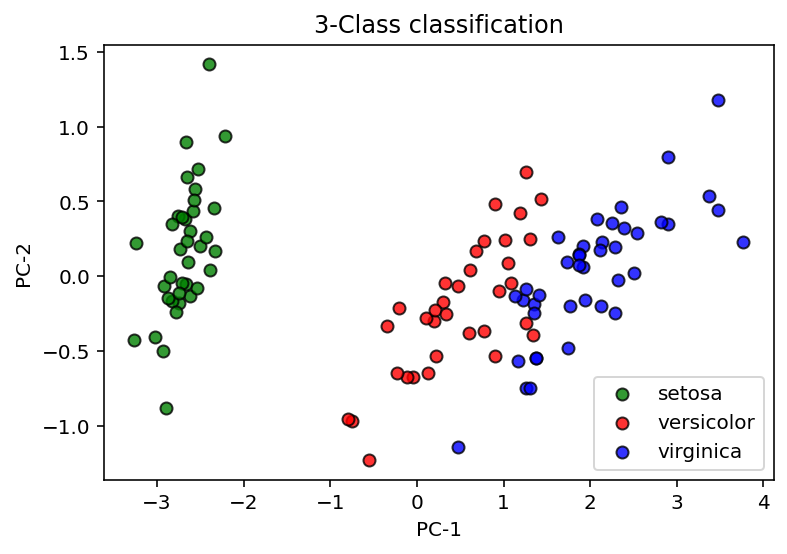

In [22]:
pca_features = ["PC-1", "PC-2"]
plot_training_points(xps_train, ys_train, pca_features, target_names, COLORS)

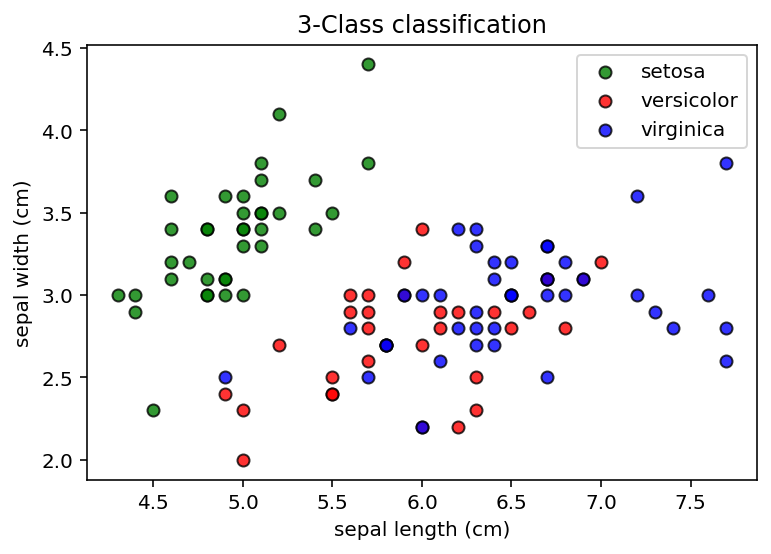

In [23]:
plot_training_points(xs_train, ys_train, features, target_names, COLORS)

On voit que l'ACP (PCA) permet de mieux discriminer visuellement les différentes classes.

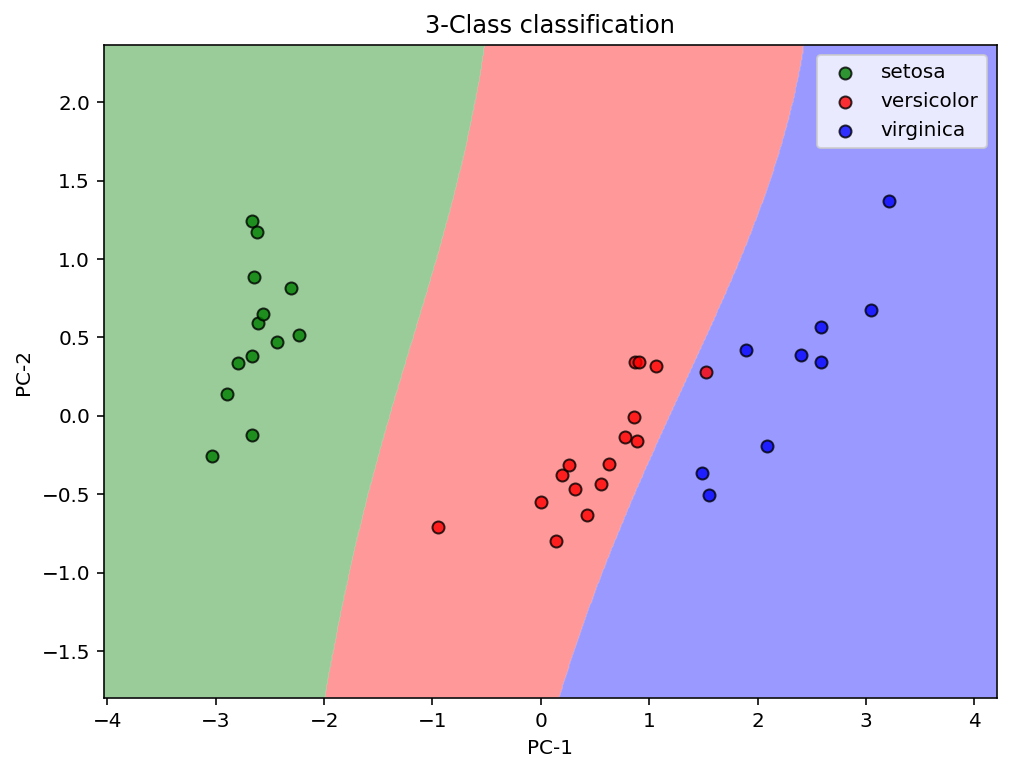

In [24]:
plot_decision_boundary(xps_test, model_p, COLORS, HOP)
plot_training_points(xps_test, ys_test, ["PC-1", "PC-2"], target_names, COLORS)

Comme attendu, la séparation en classes est meilleure avec le classifieur appliqué aux 2 premières composantes principales, plutôt qu'aux 2 premiers descripteurs.

On peut même n'utiliser que la premère composante principale – qui explique d'ailleurs 95% de la variance des descripteurs – pour obtienir une classification affichant la même performance.

| Model                   | Accuracy | Acc. PCA |
| :--                     | --:      | --:      |
| GaussianNB              | 0.8158   | 0.9737   |
| LogisticRegression      | 0.7895   | 0.9737   |
| DecisionTreeClassifier  | 0.6316   | 0.9737   |
| RandomForestClassifier  | 0.8158   | 0.9474   |
| KNeighborsRegressor     | 0.7895   | 1.0000   |
| SVC                     | 0.8158   | 0.9737   |

---